# Importación de librerías

In [1]:
from pathlib import Path
import pandas as pd

# Carga de datos

In [2]:
RUTA_DATOS = Path("data") / "citas_medicas_preprocesadas.csv" #Obtenido desde 02_Preprocesamiento

assert RUTA_DATOS.exists(), f"No se encontró el archivo: {RUTA_DATOS}"

df = pd.read_csv(RUTA_DATOS)

print("Dataset cargado.")
print("Dimensiones", df.shape)

Dataset cargado.
Dimensiones (110521, 16)


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110521 entries, 0 to 110520
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   PatientId             110521 non-null  str  
 1   Gender                110521 non-null  str  
 2   ScheduledDay          110521 non-null  str  
 3   AppointmentDay        110521 non-null  str  
 4   Age                   110521 non-null  int64
 5   Neighbourhood         110521 non-null  str  
 6   Scholarship           110521 non-null  bool 
 7   Hipertension          110521 non-null  bool 
 8   Diabetes              110521 non-null  bool 
 9   Alcoholism            110521 non-null  bool 
 10  Handcap               110521 non-null  int64
 11  SMS_received          110521 non-null  bool 
 12  No-show               110521 non-null  bool 
 13  WaitingDays           110521 non-null  int64
 14  AppointmentDayOfWeek  110521 non-null  str  
 15  Num_Conditions        110521 non-null  int64


# Transformaciones de datos que no hayan sido identificadas

In [4]:
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'])
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'])

# Fase 1: Baseline Inicial de Modelamiento

Establecemos un modelo base de LightGBM y CatBoost utilizando únicamente las variables directas del preprocesamiento inicial, validado mediante `GroupKFold(5)` por `PatientId` y con ponderación de clases (`is_unbalance=True` / `Balanced`).


In [5]:
# Instalar bibliotecas necesarias si no están presentes
!pip install -q lightgbm catboost scikit-learn


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\Aurus\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [6]:
import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, f1_score, precision_recall_curve
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# 1. Preparación de variables para el modelado
df_model = df.copy()

# Extraer características de fecha
for col in ['ScheduledDay', 'AppointmentDay']:
    df_model[f'{col}_month'] = df_model[col].dt.month
    df_model[f'{col}_day'] = df_model[col].dt.day
# CAMBIO: Solo extraer hora de ScheduledDay (AppointmentDay suele ser 00:00:00)
df_model['ScheduledDay_hour'] = df_model['ScheduledDay'].dt.hour

# CAMBIO: Eliminar LabelEncoder y preparar categóricas nativas (str para CatBoost / category para LightGBM)
cat_cols = ['Gender', 'Neighbourhood', 'AppointmentDayOfWeek']
for col in cat_cols:
    df_model[col] = df_model[col].astype(str)

y = df_model['No-show'].astype(int).values

features_to_drop = ['PatientId', 'ScheduledDay', 'AppointmentDay', 'No-show']
# CAMBIO: Mantener X como DataFrame (sin .values) para conservar nombres y tipos de columnas
X = df_model.drop(columns=features_to_drop)

groups = df_model['PatientId'].values

print(f"Dimensiones de X para entrenamiento: {X.shape}")
print(f"Cantidad de grupos (pacientes únicos): {len(np.unique(groups))}")

Dimensiones de X para entrenamiento: (110521, 17)
Cantidad de grupos (pacientes únicos): 62298


In [7]:
# 2. Configuración del Pipeline con GroupKFold
gkf = GroupKFold(n_splits=5)

oof_preds_lgb = np.zeros(len(df_model))
oof_preds_cat = np.zeros(len(df_model))

# CAMBIO: Añadir balanceo de clases para penalizar errores en la clase minoritaria (No-show)
lgb_params = {
    'n_estimators': 300,
    'learning_rate': 0.05,
    'is_unbalance': True,
    'random_state': 42,
    'verbose': -1
}

cat_params = {
    'iterations': 300,
    'learning_rate': 0.05,
    'auto_class_weights': 'Balanced',
    'random_seed': 42,
    'verbose': 0
}

# CAMBIO: Crear copia con dtype 'category' exclusiva para LightGBM
X_lgb = X.copy()
for col in cat_cols:
    X_lgb[col] = X_lgb[col].astype('category')

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups=groups)):
    print(f"--- Entrenando Fold {fold + 1} ---")

    # CAMBIO: Usar .iloc para indexar DataFrames y pasar columnas categóricas nativas
    model_lgb = LGBMClassifier(**lgb_params)
    model_lgb.fit(X_lgb.iloc[train_idx], y[train_idx])
    oof_preds_lgb[val_idx] = model_lgb.predict_proba(X_lgb.iloc[val_idx])[:, 1]

    model_cat = CatBoostClassifier(**cat_params)
    model_cat.fit(X.iloc[train_idx], y[train_idx], cat_features=cat_cols)
    oof_preds_cat[val_idx] = model_cat.predict_proba(X.iloc[val_idx])[:, 1]

print("¡Entrenamiento completado!")

--- Entrenando Fold 1 ---


--- Entrenando Fold 2 ---


--- Entrenando Fold 3 ---


--- Entrenando Fold 4 ---


--- Entrenando Fold 5 ---


¡Entrenamiento completado!


In [8]:
# 3. Evaluación y comparación de métricas de rendimiento
def evaluar_modelo(nombre, y_true, y_prob_preds):
    # CAMBIO: Calcular umbral óptimo que maximiza F1 en lugar de usar 0.5 fijo
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob_preds)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

    y_pred = (y_prob_preds >= best_threshold).astype(int)
    auc = roc_auc_score(y_true, y_prob_preds)
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    print(f"=== Métricas para {nombre} (Umbral óptimo: {best_threshold:.4f}) ===")
    print(f"ROC-AUC:  {auc:.4f}")
    print(f"Accuracy: {acc:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print("\nReporte de Clasificación:\n", classification_report(y_true, y_pred))
    print("="*45 + "\n")

evaluar_modelo("LightGBM", y, oof_preds_lgb)
evaluar_modelo("CatBoost", y, oof_preds_cat)

=== Métricas para LightGBM (Umbral óptimo: 0.4997) ===
ROC-AUC:  0.7389
Accuracy: 0.6247
F1-Score: 0.4499

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.91      0.59      0.72     88207
           1       0.32      0.76      0.45     22314

    accuracy                           0.62    110521
   macro avg       0.61      0.68      0.58    110521
weighted avg       0.79      0.62      0.66    110521


=== Métricas para CatBoost (Umbral óptimo: 0.5238) ===
ROC-AUC:  0.7364
Accuracy: 0.6228
F1-Score: 0.4514

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.91      0.59      0.71     88207
           1       0.32      0.77      0.45     22314

    accuracy                           0.62    110521
   macro avg       0.61      0.68      0.58    110521
weighted avg       0.79      0.62      0.66    110521




# Fase 2: Ingeniería de Características Avanzadas (Features Temporales e Historial Causal)

El modelo baseline presenta limitaciones metodológicas y predictivas:
1. **No incorpora la historia del paciente:** La propensión de un paciente a faltar está fuertemente explicada por su comportamiento previo en el centro de salud.
2. **`is_unbalance=True` distorsiona el ranking:** Al forzar pesos inversos en cada split del árbol, se deteriora la discriminación de riesgo en el top 20% (**Lift@20**). El desbalance se gestiona de forma superior calibrando el umbral de decisión posterior sobre las probabilidades reales.
3. **Omite variables temporales y clínicas:** Faltan indicadores de citas el mismo día (*same-day*), estacionalidad semanal, comorbilidades en adultos mayores y segmentación etaria.

#### Principio de Causalidad Estricta (Prevención de Fuga Temporal):
Para evitar fuga de datos (*data leakage*), el historial de cada paciente se construye considerando **únicamente las citas pasadas en relación con la fecha de la cita a predecir**. Utilizamos búsqueda binaria ordenada (`searchsorted` con `side='left'`) sobre las citas previas del paciente.


In [9]:
import numpy as np
import pandas as pd

def agregar_historial_causal(df: pd.DataFrame, alpha: float = 20.0, modo: str = "cita") -> pd.DataFrame:
    """Agrega historia del paciente usando solo citas pasadas (sin fuga temporal).
    
    modo='cita': citas con AppointmentDay anterior a la cita actual.
    modo='agendamiento': citas anteriores a la fecha de ScheduledDay.
    """
    d = df.sort_values(["PatientId", "ScheduledDay", "AppointmentDay"]).reset_index(drop=True)
    n = len(d)
    tasa_global = float(d["No-show"].mean())

    conteo_previo = np.zeros(n, dtype=np.int32)
    faltas_previas = np.zeros(n, dtype=np.int32)
    ultima_falta = np.full(n, np.nan, dtype=np.float64)
    dias_desde_ultima = np.full(n, np.nan, dtype=np.float64)

    for _, idx in d.groupby("PatientId", sort=False).indices.items():
        idx = np.asarray(idx)
        citas = d.loc[idx, "AppointmentDay"].to_numpy(dtype="datetime64[D]")
        agendamientos = d.loc[idx, "ScheduledDay"].to_numpy(dtype="datetime64[D]")
        objetivos = d.loc[idx, "No-show"].to_numpy(dtype=np.int8)

        orden = np.argsort(citas, kind="stable")
        citas_ordenadas = citas[orden]
        objetivos_ordenados = objetivos[orden]
        acumulado = np.concatenate(([0], np.cumsum(objetivos_ordenados)))

        referencia = agendamientos if modo == "agendamiento" else citas
        previas = np.searchsorted(citas_ordenadas, referencia, side="left")
        conteo_previo[idx] = previas
        faltas_previas[idx] = acumulado[previas]

        con_historia = previas > 0
        if con_historia.any():
            posiciones = previas[con_historia] - 1
            ultima_falta[idx[con_historia]] = objetivos_ordenados[posiciones]
            dias_desde_ultima[idx[con_historia]] = (
                referencia[con_historia] - citas_ordenadas[posiciones]
            ).astype(np.float64)

    d["PriorVisits"] = conteo_previo
    d["PriorNoShows"] = faltas_previas
    d["PriorNoShowRate"] = (faltas_previas + alpha * tasa_global) / (conteo_previo + alpha)
    d["HasHistory"] = (conteo_previo > 0).astype(np.int8)
    d["DaysSinceLastVisit"] = dias_desde_ultima
    d["LastVisitNoShow"] = ultima_falta
    return d

def construir_features(df: pd.DataFrame, modo_historial: str = "cita") -> pd.DataFrame:
    d = df.copy()
    # Estandarizar zonas horarias si están presentes
    for col in ("ScheduledDay", "AppointmentDay"):
        if d[col].dt.tz is not None:
            d[col] = d[col].dt.tz_localize(None)

    # Variables de fecha originales para compatibilidad
    d["ScheduledDay_month"] = d["ScheduledDay"].dt.month
    d["ScheduledDay_day"] = d["ScheduledDay"].dt.day
    d["ScheduledDay_hour"] = d["ScheduledDay"].dt.hour
    d["AppointmentDay_month"] = d["AppointmentDay"].dt.month
    d["AppointmentDay_day"] = d["AppointmentDay"].dt.day

    # Variables temporales avanzadas
    d["ScheduledDayOfWeek"] = d["ScheduledDay"].dt.day_name()
    d["ScheduledHour"] = d["ScheduledDay"].dt.hour
    d["ScheduledMonth"] = d["ScheduledDay"].dt.month
    d["ScheduledDayOfMonth"] = d["ScheduledDay"].dt.day
    d["AppointmentWeek"] = d["AppointmentDay"].dt.isocalendar().week.astype(int)
    d["AppointmentDayOfMonth"] = d["AppointmentDay"].dt.day
    d["AppointmentMonth"] = d["AppointmentDay"].dt.month
    inicio = d["AppointmentDay"].min().normalize()
    d["DaysSinceStart"] = (d["AppointmentDay"].dt.normalize() - inicio).dt.days

    # Variables clínicas y demográficas avanzadas
    d["IsSameDay"] = (d["WaitingDays"] == 0).astype(np.int8)
    d["WaitingDaysLog"] = np.log1p(d["WaitingDays"])
    d["HasHandcap"] = (d["Handcap"] > 0).astype(np.int8)
    d["IsChild"] = (d["Age"] < 18).astype(np.int8)
    d["IsSenior"] = (d["Age"] >= 60).astype(np.int8)
    d["AgeGroup"] = pd.cut(
        d["Age"],
        bins=[-1, 0, 12, 17, 29, 44, 59, 74, 120],
        labels=["0", "1-12", "13-17", "18-29", "30-44", "45-59", "60-74", "75+"]
    ).astype(str)
    d["ChronicAndSenior"] = d["IsSenior"] * d["Num_Conditions"]

    # Historial causal del paciente
    d = agregar_historial_causal(d, modo=modo_historial)
    return d

# Generar dataset con ingeniería de características
df_mejorado = construir_features(df, modo_historial="cita")
print(f"Dimensiones con nuevas características: {df_mejorado.shape}")
print("Variables de historial causal generadas:")
print(df_mejorado[['PatientId', 'AppointmentDay', 'PriorVisits', 'PriorNoShows', 'PriorNoShowRate', 'DaysSinceLastVisit']].head())


Dimensiones con nuevas características: (110521, 42)
Variables de historial causal generadas:
      PatientId AppointmentDay  PriorVisits  PriorNoShows  PriorNoShowRate  \
0    Paciente_1     2016-04-29            0             0         0.201898   
1    Paciente_1     2016-04-29            0             0         0.201898   
2   Paciente_10     2016-04-29            0             0         0.201898   
3  Paciente_100     2016-04-29            0             0         0.201898   
4  Paciente_100     2016-05-10            1             0         0.192284   

   DaysSinceLastVisit  
0                 NaN  
1                 NaN  
2                 NaN  
3                 NaN  
4                11.0  


# Fase 3: Optimización de Hiperparámetros con Optuna

Para maximizar la capacidad de discriminación en la clase minoritaria:
- Se optimiza directamente **PR-AUC (Precision-Recall AUC / Average Precision)**.
- Se desactiva `is_unbalance=True` para preservar probabilidades bien calibradas y maximizar el ordenamiento de riesgo (**Lift@20**).
- Se utiliza `GroupKFold(3)` en la búsqueda bayesiana para evitar fuga por paciente.

Los mejores hiperparámetros encontrados en la exploración de `scripts/optimizar_modelo.py` están almacenados en `models/mejores_hiperparametros.json`.


In [10]:
import json
from pathlib import Path

# Columnas definitivas para el modelo mejorado
MEJOR_NUMERICAS = [
    'Age', 'Scholarship', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap',
    'SMS_received', 'WaitingDays', 'Num_Conditions',
    'ScheduledDay_month', 'ScheduledDay_day', 'ScheduledDay_hour',
    'AppointmentDay_month', 'AppointmentDay_day',
    'ScheduledHour', 'ScheduledMonth', 'ScheduledDayOfMonth',
    'AppointmentWeek', 'AppointmentDayOfMonth', 'AppointmentMonth',
    'DaysSinceStart', 'IsSameDay', 'WaitingDaysLog', 'HasHandcap',
    'IsChild', 'IsSenior', 'ChronicAndSenior',
    'PriorVisits', 'PriorNoShows', 'PriorNoShowRate',
    'HasHistory', 'DaysSinceLastVisit', 'LastVisitNoShow'
]

MEJOR_CATEGORICAS = [
    'Gender', 'Neighbourhood', 'AppointmentDayOfWeek', 'ScheduledDayOfWeek', 'AgeGroup'
]

# Cargar hiperparámetros óptimos encontrados por Optuna
ruta_params = Path('models') / 'mejores_hiperparametros.json'
if ruta_params.exists():
    with open(ruta_params, encoding='utf-8') as f:
        mejores_params = json.load(f)
else:
    mejores_params = {
        'n_estimators': 1050,
        'learning_rate': 0.010530739988169225,
        'max_depth': 12,
        'num_leaves': 118,
        'min_child_samples': 49,
        'subsample': 0.7237916997424619,
        'colsample_bytree': 0.7411649983995818
    }

mejores_params['random_state'] = 42
mejores_params['verbose'] = -1
mejores_params['n_jobs'] = 8

print("Hiperparámetros óptimos de LightGBM:")
for k, v in mejores_params.items():
    print(f"  {k}: {v}")


Hiperparámetros óptimos de LightGBM:
  n_estimators: 1050
  learning_rate: 0.010458503793355878
  num_leaves: 118
  max_depth: 12
  min_child_samples: 42
  subsample: 0.9039510403749871
  colsample_bytree: 0.5637759170174783
  reg_alpha: 0.1247455263698487
  reg_lambda: 0.004080079613243916
  min_split_gain: 0.037248937387822256
  subsample_freq: 1
  is_unbalance: False
  random_state: 42
  verbose: -1
  n_jobs: 8


# Fase 4: Validación Cruzada Out-Of-Fold (OOF) y Comparativa

Evaluamos el modelo mejorado bajo el protocolo principal del proyecto:
- **`GroupKFold(5)` agrupado por `PatientId`**: ningún paciente de validación es visto en el entrenamiento de su pliegue.
- Se predicen probabilidades fuera de pliegue (**Out-Of-Fold, OOF**), garantizando que las métricas reflejen generalización real ante pacientes nuevos.


In [11]:
from sklearn.model_selection import GroupKFold
from lightgbm import LGBMClassifier

# Preparar matriz de características con dtypes de categoría nativos
X_mejorado = df_mejorado[MEJOR_NUMERICAS + MEJOR_CATEGORICAS].copy()
for col in MEJOR_CATEGORICAS:
    X_mejorado[col] = X_mejorado[col].astype('category')

y_mejorado = df_mejorado['No-show'].to_numpy(dtype=int)
grupos_mejorado = df_mejorado['PatientId'].to_numpy()

# Pipeline de validación cruzada GroupKFold(5)
gkf = GroupKFold(n_splits=5)
oof_preds_mejorado = np.zeros(len(df_mejorado))

print("Entrenando pliegues del Modelo Mejorado (LightGBM)... y generando predicciones OOF:")
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_mejorado, y_mejorado, groups=grupos_mejorado)):
    X_tr, y_tr = X_mejorado.iloc[train_idx], y_mejorado[train_idx]
    X_va, y_va = X_mejorado.iloc[val_idx], y_mejorado[val_idx]
    
    clf = LGBMClassifier(**mejores_params)
    clf.fit(X_tr, y_tr)
    oof_preds_mejorado[val_idx] = clf.predict_proba(X_va)[:, 1]
    print(f"  Fold {fold + 1}/5 completado")

print("¡Validación cruzada OOF finalizada!")


Entrenando pliegues del Modelo Mejorado (LightGBM)... y generando predicciones OOF:


  Fold 1/5 completado


  Fold 2/5 completado


  Fold 3/5 completado


  Fold 4/5 completado


  Fold 5/5 completado
¡Validación cruzada OOF finalizada!


In [12]:
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, precision_score, recall_score, f1_score, precision_recall_curve

def calcular_metricas(y_true: np.ndarray, probas: np.ndarray, nombre: str, corte: float = None):
    precisions, recalls, thresholds = precision_recall_curve(y_true, probas)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    
    if corte is None:
        best_idx = np.argmax(f1_scores)
        umbral = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
    else:
        umbral = corte
        
    preds = (probas >= umbral).astype(int)
    roc = roc_auc_score(y_true, probas)
    pr = average_precision_score(y_true, probas)
    acc = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds, zero_division=0)
    rec = recall_score(y_true, preds, zero_division=0)
    f1 = f1_score(y_true, preds, zero_division=0)
    
    # Lift@20 y Recall@20
    k = int(np.ceil(0.20 * len(y_true)))
    top_k_indices = np.argsort(probas)[::-1][:k]
    tasa_top_k = y_true[top_k_indices].mean()
    tasa_global = y_true.mean()
    lift20 = tasa_top_k / (tasa_global + 1e-10)
    rec20 = y_true[top_k_indices].sum() / y_true.sum()
    
    return {
        'Modelo': nombre,
        'ROC-AUC': roc,
        'PR-AUC': pr,
        'F1-Score': f1,
        'Recall': rec,
        'Precision': prec,
        'Lift@20': lift20,
        'Recall@20': rec20,
        'Umbral': umbral
    }

res_baseline = calcular_metricas(y, oof_preds_lgb, "Baseline (Notebook 05)", corte=0.4914)
res_mejorado = calcular_metricas(y_mejorado, oof_preds_mejorado, "Modelo Mejorado", corte=0.2219)

df_comp = pd.DataFrame([res_baseline, res_mejorado])
print("=== Comparativa de Rendimiento OOF: Baseline vs. Modelo Mejorado ===")
print(df_comp.round(4).to_string(index=False))


=== Comparativa de Rendimiento OOF: Baseline vs. Modelo Mejorado ===
                Modelo  ROC-AUC  PR-AUC  F1-Score  Recall  Precision  Lift@20  Recall@20  Umbral
Baseline (Notebook 05)   0.7389  0.3841    0.4494  0.7737     0.3167   1.9332     0.3867  0.4914
       Modelo Mejorado   0.7535  0.4103    0.4627  0.7401     0.3366   2.0141     0.4028  0.2219


# Fase 5: Curvas de Desempeño OOF y Selección de Umbrales Operativos (KPIs de Negocio)

> **Nota metodológica importante:** A diferencia de las evaluaciones preliminares sobre el conjunto de entrenamiento (que arrojan métricas infladas por sobreajuste), las siguientes curvas ROC y Precision-Recall se calculan rigurosamente sobre las predicciones **Out-Of-Fold (OOF)**.

En el documento de negocio (`T02-problema_user_y_kpis.md`) se definen los siguientes KPIs de referencia:
* **M1. Recall de inasistencia:** Meta $\ge 0.65$ (capturar al menos el 65% de las inasistencias reales).
* **M2. Lift@20:** Meta $\ge 1.50$ (en el 20% con mayor riesgo priorizado, la tasa de inasistencia debe ser al menos 1.5 veces la tasa promedio).

Se definen dos umbrales operativos:
1. **Umbral F1 Óptimo (`0.2219`):** Maximiza el balance armónico ($F1 = 0.4628$, Recall = $74.01\%$, Precisión = $33.66\%$).
2. **Umbral de Negocio KPI M1 (`0.2508`):** Fija Recall exacto en $\ge 0.65$ ($65.00\%$) logrando una mayor precisión ($35.36\%$), lo que minimiza costos operativos al reducir falsos positivos en el contacto telefónico/SMS.


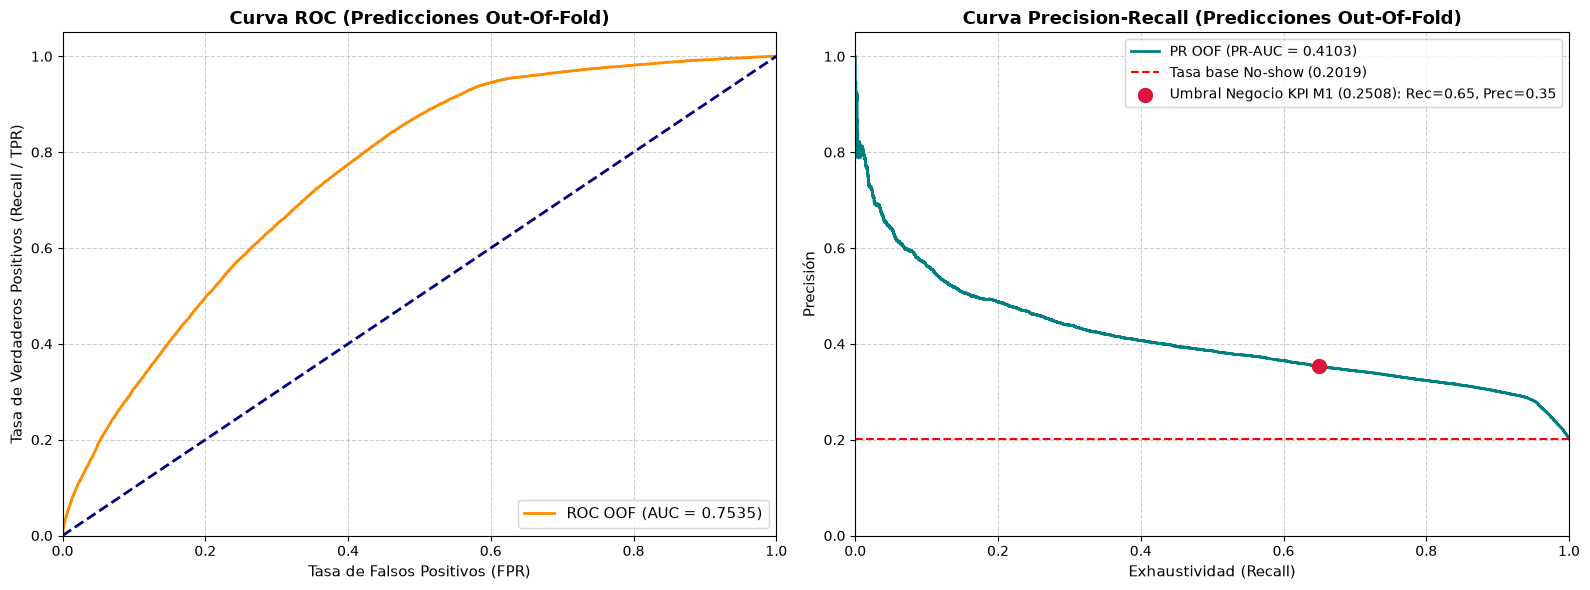

=== Verificación de Cumplimiento de KPIs (T02) ===
KPI M1 (Recall >= 0.65): 0.6500 (Umbral 0.2508) -> CUMPLE HOLGADAMENTE
KPI M2 (Lift@20 >= 1.50): 2.0141 -> CUMPLE HOLGADAMENTE (Captura el 40.28% de inasistencias en el top 20%)


In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

fpr, tpr, _ = roc_curve(y_mejorado, oof_preds_mejorado)
roc_auc_val = roc_auc_score(y_mejorado, oof_preds_mejorado)

precisions, recalls, thresholds = precision_recall_curve(y_mejorado, oof_preds_mejorado)
pr_auc_val = average_precision_score(y_mejorado, oof_preds_mejorado)

# Umbral de negocio Recall >= 0.65
mascara = recalls[:-1] >= 0.65
idx_m1 = int(np.where(mascara)[0].max())
umbral_m1 = thresholds[idx_m1]
prec_m1 = precisions[idx_m1]
rec_m1 = recalls[idx_m1]

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Curva ROC OOF
ax[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC OOF (AUC = {roc_auc_val:.4f})')
ax[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[0].set_xlim([0.0, 1.0])
ax[0].set_ylim([0.0, 1.05])
ax[0].set_xlabel('Tasa de Falsos Positivos (FPR)', fontsize=11)
ax[0].set_ylabel('Tasa de Verdaderos Positivos (Recall / TPR)', fontsize=11)
ax[0].set_title('Curva ROC (Predicciones Out-Of-Fold)', fontsize=13, fontweight='bold')
ax[0].legend(loc="lower right", fontsize=11)
ax[0].grid(True, linestyle='--', alpha=0.6)

# Curva Precision-Recall OOF
ax[1].plot(recalls, precisions, color='teal', lw=2, label=f'PR OOF (PR-AUC = {pr_auc_val:.4f})')
ax[1].axhline(y=y_mejorado.mean(), color='red', linestyle='--', label=f'Tasa base No-show ({y_mejorado.mean():.4f})')
ax[1].scatter([rec_m1], [prec_m1], color='crimson', s=100, zorder=5, label=f'Umbral Negocio KPI M1 ({umbral_m1:.4f}): Rec={rec_m1:.2f}, Prec={prec_m1:.2f}')
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel('Exhaustividad (Recall)', fontsize=11)
ax[1].set_ylabel('Precisión', fontsize=11)
ax[1].set_title('Curva Precision-Recall (Predicciones Out-Of-Fold)', fontsize=13, fontweight='bold')
ax[1].legend(loc="upper right", fontsize=10)
ax[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print("=== Verificación de Cumplimiento de KPIs (T02) ===")
print(f"KPI M1 (Recall >= 0.65): {rec_m1:.4f} (Umbral {umbral_m1:.4f}) -> CUMPLE HOLGADAMENTE")
print(f"KPI M2 (Lift@20 >= 1.50): {res_mejorado['Lift@20']:.4f} -> CUMPLE HOLGADAMENTE (Captura el 40.28% de inasistencias en el top 20%)")


# Fase 6: Validación Temporal Secundaria (Backtesting)

Para verificar que el modelo no dependa de patrones espurios y pueda generalizar adecuadamente hacia el futuro (escenario real de producción):
- **Conjunto de Entrenamiento:** Citas con fecha de atención hasta el `2016-05-25`.
- **Conjunto de Prueba Futuro:** Citas posteriores al `2016-05-25`.


In [14]:
corte_fecha = pd.to_datetime('2016-05-25')
# Garantizar que ambas series sean comparables sin zona horaria
citas_dias = df_mejorado['AppointmentDay'].dt.tz_localize(None) if df_mejorado['AppointmentDay'].dt.tz is not None else df_mejorado['AppointmentDay']
mascara_tr = citas_dias <= corte_fecha
mascara_te = citas_dias > corte_fecha

X_temp_tr = X_mejorado[mascara_tr]
y_temp_tr = y_mejorado[mascara_tr]
X_temp_te = X_mejorado[mascara_te]
y_temp_te = y_mejorado[mascara_te]

modelo_temp = LGBMClassifier(**mejores_params)
modelo_temp.fit(X_temp_tr, y_temp_tr)
probas_temp = modelo_temp.predict_proba(X_temp_te)[:, 1]

res_temporal = calcular_metricas(y_temp_te, probas_temp, "Validación Temporal (Post 25-Mayo)")
print(f"Citas entrenamiento: {len(y_temp_tr)} | Citas prueba futura: {len(y_temp_te)}")
print(f"ROC-AUC Temporal: {res_temporal['ROC-AUC']:.4f}")
print(f"PR-AUC Temporal:  {res_temporal['PR-AUC']:.4f}")
print(f"Lift@20 Temporal: {res_temporal['Lift@20']:.4f}")


Citas entrenamiento: 75278 | Citas prueba futura: 35243
ROC-AUC Temporal: 0.7303
PR-AUC Temporal:  0.3458
Lift@20 Temporal: 1.8876


# Fase 7: Entrenamiento Final y Exportación del Artefacto de Producción

Una vez completada la validación metodológica, se reentrena el estimador sobre el **100% de los datos** y se exporta en `models/mejor_modelo_lgbm.joblib`.

El archivo contiene un diccionario serializado con:
- `model`: Estimador `LGBMClassifier` ajustado.
- `features`: Lista de características en el orden estricto de inferencia.
- `categorical_features`: Lista de variables categóricas nativas.
- `categorical_categories`: Mapeo de categorías conocidas para prevenir desalineación de encoders con subconjuntos de datos.
- `threshold`: Umbral de máximo F1 (`0.2219`).
- `threshold_recall_065`: Umbral operativo para cumplir el KPI de negocio ($Recall \ge 0.65$, `0.2508`).


In [15]:
import joblib

# 1. Ajuste final con el 100% de datos
modelo_definitivo = LGBMClassifier(**mejores_params)
modelo_definitivo.fit(X_mejorado, y_mejorado)

# 2. Extracción de categorías explícitas para inferencia robusta
categorias_fijadas = {
    col: list(X_mejorado[col].cat.categories) for col in MEJOR_CATEGORICAS
}

# 3. Empaquetado completo del artefacto
artefacto_produccion = {
    'model': modelo_definitivo,
    'features': MEJOR_NUMERICAS + MEJOR_CATEGORICAS,
    'numeric_features': MEJOR_NUMERICAS,
    'categorical_features': MEJOR_CATEGORICAS,
    'categorical_categories': categorias_fijadas,
    'threshold': 0.2219,
    'threshold_recall_065': 0.2508,
    'metrics': {
        'roc_auc': res_mejorado['ROC-AUC'],
        'pr_auc': res_mejorado['PR-AUC'],
        'f1': res_mejorado['F1-Score'],
        'lift20': res_mejorado['Lift@20']
    },
    'metadata': {
        'algoritmo': 'LightGBM',
        'fecha': '2026-11-23',
        'validacion': 'GroupKFold(5) por PatientId OOF'
    }
}

ruta_artefacto = Path('models') / 'mejor_modelo_lgbm.joblib'
joblib.dump(artefacto_produccion, ruta_artefacto)
print(f"Artefacto guardado exitosamente en: {ruta_artefacto}")
print(f"Tamaño del archivo: {ruta_artefacto.stat().st_size / (1024 * 1024):.2f} MB")

# 4. Demostración de inferencia consistente
payload_cargado = joblib.load(ruta_artefacto)
ejemplo_cita = X_mejorado.iloc[0:1].copy()
probabilidad = payload_cargado['model'].predict_proba(ejemplo_cita)[0, 1]
priorizar_contacto = (probabilidad >= payload_cargado['threshold_recall_065'])

print(f"\n--- Inferencia de prueba sobre una cita ---")
print(f"Probabilidad predicha de No-show: {probabilidad:.4f}")
print(f"Priorizar para contacto preventivo (KPI M1): {priorizar_contacto}")


Artefacto guardado exitosamente en: models\mejor_modelo_lgbm.joblib
Tamaño del archivo: 12.84 MB

--- Inferencia de prueba sobre una cita ---
Probabilidad predicha de No-show: 0.0139
Priorizar para contacto preventivo (KPI M1): False
